In [1]:
from pathlib import Path
import sys

PROJECT_ROOT = Path.cwd().parent

sys.path.append(str(PROJECT_ROOT))

from preprocessing.dataset import IndustrialDefectDataset

print("Dataset class imported successfully!")

Dataset class imported successfully!


In [2]:
from torchvision import transforms
from torchvision.transforms import InterpolationMode

image_transform = transforms.Compose([
    transforms.Resize(
        (256, 256),
        interpolation=InterpolationMode.BILINEAR
    ),
    transforms.ToTensor()
])

mask_transform = transforms.Compose([
    transforms.Resize(
        (256, 256),
        interpolation=InterpolationMode.NEAREST
    ),
    transforms.PILToTensor()
])

In [17]:
mvtec_train = IndustrialDefectDataset(
    PROJECT_ROOT / "splits" / "mvtec_unsupervised.csv",
    transform=image_transform,
    mask_transform=mask_transform,
    normal_only=True,
    split="train"
)

print("MVTec training samples:", len(mvtec_train))

MVTec training samples: 3629


In [18]:
sample = mvtec_train[0]

print("Image shape:", sample["image"].shape)
print("Label:", sample["label"])
print("Category:", sample["category"])
print("Image path:", sample["image_path"])
print("Mask shape:", sample["mask"].shape)

Image shape: torch.Size([3, 256, 256])
Label: 0
Category: bottle
Image path: C:\Users\rimjh\IndustrialDefectProject\datasets\mvtec_anomaly_detection\bottle\train\good\000.png
Mask shape: torch.Size([256, 256])


In [19]:
from torch.utils.data import DataLoader

train_loader = DataLoader(
    mvtec_train,
    batch_size=8,
    shuffle=True,
    num_workers=0
)

batch = next(iter(train_loader))

print("Image batch shape:", batch["image"].shape)
print("Mask batch shape:", batch["mask"].shape)
print("Labels:", batch["label"])
print("Categories:", batch["category"])

Image batch shape: torch.Size([8, 3, 256, 256])
Mask batch shape: torch.Size([8, 256, 256])
Labels: tensor([0, 0, 0, 0, 0, 0, 0, 0])
Categories: ['transistor', 'leather', 'leather', 'wood', 'pill', 'tile', 'screw', 'screw']


In [20]:
visa_train = IndustrialDefectDataset(
    PROJECT_ROOT / "splits" / "visa_unsupervised.csv",
    transform=image_transform,
    mask_transform=mask_transform,
    normal_only=True,
    split="train"
)

print("VisA training samples:", len(visa_train))

VisA training samples: 8659


In [7]:
visa_loader = DataLoader(
    visa_train,
    batch_size=8,
    shuffle=True,
    num_workers=0
)

visa_batch = next(iter(visa_loader))

print("VisA image batch shape:", visa_batch["image"].shape)
print("VisA mask batch shape:", visa_batch["mask"].shape)
print("VisA labels:", visa_batch["label"])
print("VisA categories:", visa_batch["category"])

VisA image batch shape: torch.Size([8, 3, 256, 256])
VisA mask batch shape: torch.Size([8, 256, 256])
VisA labels: tensor([0, 0, 0, 0, 0, 0, 0, 0])
VisA categories: ['pcb4', 'pcb1', 'pcb1', 'macaroni1', 'pcb1', 'pcb2', 'macaroni2', 'pcb2']


In [8]:
from pathlib import Path
import pandas as pd

PROJECT_ROOT = Path.cwd().parent

files_to_fix = [
    PROJECT_ROOT / "metadata" / "mvtec_metadata.csv",
    PROJECT_ROOT / "metadata" / "visa_metadata.csv",
    PROJECT_ROOT / "splits" / "mvtec_unsupervised.csv",
    PROJECT_ROOT / "splits" / "visa_unsupervised.csv",
]

for file in files_to_fix:
    print(file)

c:\Users\rimjh\IndustrialDefectProject\metadata\mvtec_metadata.csv
c:\Users\rimjh\IndustrialDefectProject\metadata\visa_metadata.csv
c:\Users\rimjh\IndustrialDefectProject\splits\mvtec_unsupervised.csv
c:\Users\rimjh\IndustrialDefectProject\splits\visa_unsupervised.csv


In [9]:
for file in files_to_fix:
    backup = file.with_name(file.stem + "_backup.csv")
    
    df = pd.read_csv(file)
    df.to_csv(backup, index=False)
    
    print("Backup created:", backup.name)

Backup created: mvtec_metadata_backup.csv
Backup created: visa_metadata_backup.csv
Backup created: mvtec_unsupervised_backup.csv
Backup created: visa_unsupervised_backup.csv


In [10]:
OLD_ROOT = str(PROJECT_ROOT).replace("\\", "/") + "/"

for file in files_to_fix:
    df = pd.read_csv(file)

    for column in ["image_path", "mask_path"]:
        if column in df.columns:
            df[column] = (
                df[column]
                .fillna("")
                .astype(str)
                .str.replace("\\", "/", regex=False)
                .str.replace(OLD_ROOT, "", regex=False)
            )

    df.to_csv(file, index=False)

    print("Updated:", file.name)

Updated: mvtec_metadata.csv
Updated: visa_metadata.csv
Updated: mvtec_unsupervised.csv
Updated: visa_unsupervised.csv


In [11]:
df = pd.read_csv(
    PROJECT_ROOT / "metadata" / "mvtec_metadata.csv"
)

print(df["image_path"].iloc[0])
print(df["mask_path"].iloc[0])

datasets/mvtec_anomaly_detection/bottle/train/good/000.png
nan


In [12]:
print(df["image_path"].head(3).to_list())

['datasets/mvtec_anomaly_detection/bottle/train/good/000.png', 'datasets/mvtec_anomaly_detection/bottle/train/good/001.png', 'datasets/mvtec_anomaly_detection/bottle/train/good/002.png']


In [13]:
from torch.utils.data import DataLoader

train_loader = DataLoader(
    mvtec_train,
    batch_size=8,
    shuffle=True,
    num_workers=0
)

batch = next(iter(train_loader))

print("Image batch shape:", batch["image"].shape)
print("Mask batch shape:", batch["mask"].shape)
print("Labels:", batch["label"])
print("Categories:", batch["category"])

Image batch shape: torch.Size([8, 3, 256, 256])
Mask batch shape: torch.Size([8, 256, 256])
Labels: tensor([0, 0, 0, 0, 0, 0, 0, 0])
Categories: ['tile', 'bottle', 'leather', 'tile', 'tile', 'pill', 'pill', 'bottle']


In [14]:
visa_train = IndustrialDefectDataset(
    PROJECT_ROOT / "splits" / "visa_unsupervised.csv",
    transform=image_transform,
    mask_transform=mask_transform,
    normal_only=True,
    split="train"
)

print("VisA training samples:", len(visa_train))

VisA training samples: 8659


In [15]:
visa_loader = DataLoader(
    visa_train,
    batch_size=8,
    shuffle=True,
    num_workers=0
)

batch = next(iter(visa_loader))

print("Image batch shape:", batch["image"].shape)
print("Mask batch shape:", batch["mask"].shape)
print("Labels:", batch["label"])
print("Categories:", batch["category"])

Image batch shape: torch.Size([8, 3, 256, 256])
Mask batch shape: torch.Size([8, 256, 256])
Labels: tensor([0, 0, 0, 0, 0, 0, 0, 0])
Categories: ['pcb2', 'macaroni2', 'pipe_fryum', 'pcb3', 'pcb1', 'pcb2', 'pcb4', 'capsules']


In [22]:

[name for name, obj in globals().items()
 if "loader" in name.lower() and not name.startswith("_")]


['DataLoader', 'train_loader', 'visa_loader']

In [23]:

from pathlib import Path
import pandas as pd
from torch.utils.data import DataLoader
from torchvision import transforms

# Project paths
PROJECT_ROOT = Path(r"C:\Users\rimjh\IndustrialDefectProject")
METADATA_PATH = PROJECT_ROOT / "metadata" / "mvtec_metadata.csv"

# Image preprocessing: resize to 256x256 and normalize
image_transform = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# Mask preprocessing: nearest-neighbor resize
mask_transform = transforms.Compose([
    transforms.Resize(
        (256, 256),
        interpolation=transforms.InterpolationMode.NEAREST
    ),
    transforms.ToTensor()
])

# Check metadata file exists
assert METADATA_PATH.exists(), f"Metadata not found: {METADATA_PATH}"

# Inspect the metadata columns and split values
mvtec_metadata = pd.read_csv(METADATA_PATH)
print("Metadata columns:", mvtec_metadata.columns.tolist())

if "split" in mvtec_metadata.columns:
    print("Split values:", mvtec_metadata["split"].value_counts().to_dict())

# Create dataset using your existing class
mvtec_dataset = IndustrialDefectDataset(
    metadata_csv=METADATA_PATH,
    transform=image_transform,
    mask_transform=mask_transform
)

# Create DataLoader
mvtec_loader = DataLoader(
    mvtec_dataset,
    batch_size=8,
    shuffle=False,
    num_workers=0
)

print("MVTec dataset samples:", len(mvtec_dataset))
print("MVTec DataLoader created successfully!")


Metadata columns: ['dataset', 'category', 'defect_type', 'label', 'image_path', 'mask_path', 'split']
Split values: {'train': 3629, 'test': 1725}
MVTec dataset samples: 5354
MVTec DataLoader created successfully!


In [25]:

[name for name, obj in globals().items()
 if "loader" in name.lower() and not name.startswith("_")]


['DataLoader', 'train_loader', 'visa_loader', 'mvtec_loader']

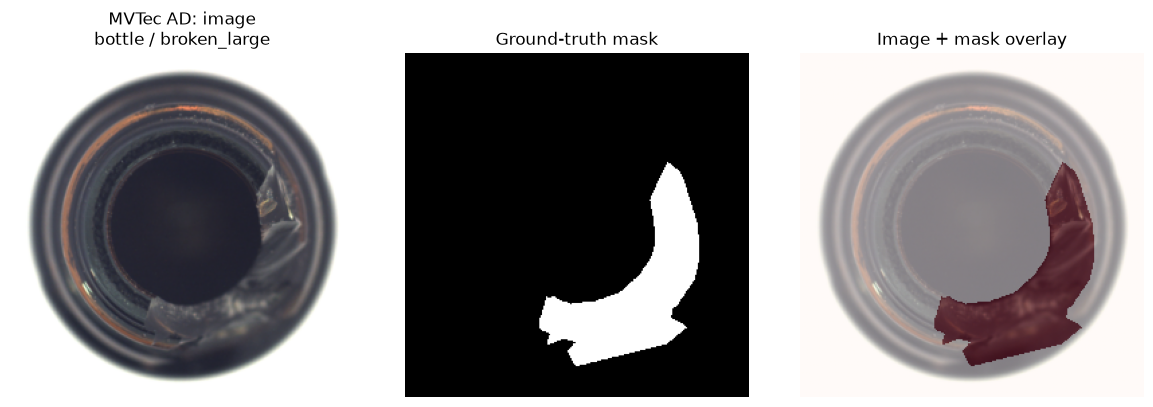

Dataset: MVTec AD
Category: bottle
Defect type: broken_large
Label: 1
Image shape: (3, 256, 256)
Mask shape: (256, 256)
Mask values: [0.0, 1.0]
No defective sample (label=1) found in VisA loader.


In [26]:

import matplotlib.pyplot as plt
import torch

# Get one batch from each DataLoader
# Assumes your notebook already defines mvtec_loader and visa_loader.

def show_defective_sample(loader, dataset_name):
    found = False

    for batch in loader:
        labels = batch["label"]
        labels = labels.tolist() if torch.is_tensor(labels) else list(labels)

        for i, label in enumerate(labels):
            if int(label) == 1:  # 1 = anomaly/defective
                image = batch["image"][i].detach().cpu()
                mask = batch["mask"][i].detach().cpu()

                # Convert image from [C, H, W] to [H, W, C]
                image = image.permute(1, 2, 0).numpy()

                # If the image was normalized, reverse ImageNet normalization
                mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
                std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)
                image_tensor = batch["image"][i].detach().cpu()
                image = (image_tensor * std + mean).clamp(0, 1)
                image = image.permute(1, 2, 0).numpy()

                category = batch["category"][i]
                defect_type = batch["defect_type"][i]

                fig, axes = plt.subplots(1, 3, figsize=(12, 4))
                axes[0].imshow(image)
                axes[0].set_title(f"{dataset_name}: image\n{category} / {defect_type}")

                axes[1].imshow(mask.numpy(), cmap="gray", vmin=0, vmax=1)
                axes[1].set_title("Ground-truth mask")

                # Overlay mask in red on the image
                axes[2].imshow(image)
                axes[2].imshow(mask.numpy(), cmap="Reds", alpha=0.45, vmin=0, vmax=1)
                axes[2].set_title("Image + mask overlay")

                for ax in axes:
                    ax.axis("off")

                plt.tight_layout()
                plt.show()

                print(f"Dataset: {dataset_name}")
                print(f"Category: {category}")
                print(f"Defect type: {defect_type}")
                print(f"Label: {label}")
                print(f"Image shape: {tuple(batch['image'][i].shape)}")
                print(f"Mask shape: {tuple(mask.shape)}")
                print(f"Mask values: {torch.unique(mask).tolist()}")

                found = True
                return

    if not found:
        print(f"No defective sample (label=1) found in {dataset_name} loader.")


show_defective_sample(mvtec_loader, "MVTec AD")
show_defective_sample(visa_loader, "VisA")


In [27]:
print("VisA dataset size:", len(visa_loader.dataset))
print("VisA dataset class:", type(visa_loader.dataset).__name__)

# Inspect labels from the first few batches
for batch in visa_loader:
    print("Labels:", batch["label"].tolist())
    print("Categories:", batch["category"])
    break

VisA dataset size: 8659
VisA dataset class: IndustrialDefectDataset
Labels: [0, 0, 0, 0, 0, 0, 0, 0]
Categories: ['candle', 'pcb1', 'macaroni1', 'pipe_fryum', 'pcb2', 'cashew', 'candle', 'pcb4']


In [28]:

import pandas as pd

visa_df = visa_loader.dataset.metadata

print("Label counts:")
print(visa_df["label"].value_counts(dropna=False))

print("\nSplit counts:")
if "split" in visa_df.columns:
    print(visa_df["split"].value_counts(dropna=False))


Label counts:
label
0    8659
Name: count, dtype: int64

Split counts:
split
train    8659
Name: count, dtype: int64


In [29]:

from pathlib import Path
import pandas as pd

PROJECT_ROOT = Path(r"C:\Users\rimjh\IndustrialDefectProject")
visa_metadata_path = PROJECT_ROOT / "metadata" / "visa_metadata.csv"

visa_df = pd.read_csv(visa_metadata_path)

print("Columns:", visa_df.columns.tolist())

for col in ["split", "label", "category", "image_path", "mask_path"]:
    if col in visa_df.columns:
        print(f"\n{col}:")
        print(visa_df[col].value_counts(dropna=False).head(10))


Columns: ['dataset', 'category', 'defect_type', 'label', 'image_path', 'mask_path', 'split']

split:
split
train    8659
test     2162
Name: count, dtype: int64

label:
label
0    9621
1    1200
Name: count, dtype: int64

category:
category
pcb3          1106
pcb4          1105
pcb1          1104
pcb2          1101
candle        1100
macaroni1     1100
macaroni2     1100
capsules       702
chewinggum     603
cashew         600
Name: count, dtype: int64

image_path:
image_path
datasets/VisA_20220922/candle/Data/Images/Normal/0000.JPG    1
datasets/VisA_20220922/candle/Data/Images/Normal/0001.JPG    1
datasets/VisA_20220922/candle/Data/Images/Normal/0002.JPG    1
datasets/VisA_20220922/candle/Data/Images/Normal/0003.JPG    1
datasets/VisA_20220922/candle/Data/Images/Normal/0004.JPG    1
datasets/VisA_20220922/candle/Data/Images/Normal/0005.JPG    1
datasets/VisA_20220922/candle/Data/Images/Normal/0006.JPG    1
datasets/VisA_20220922/candle/Data/Images/Normal/0007.JPG    1
datasets/VisA_2

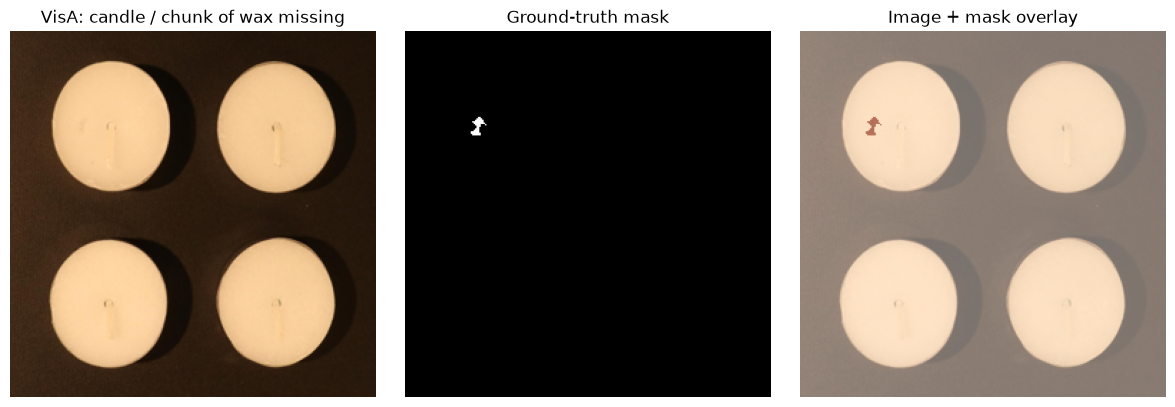

Category: candle
Defect type: chunk of wax missing
Label: 1
Image path: C:\Users\rimjh\IndustrialDefectProject\datasets\VisA_20220922\candle\Data\Images\Anomaly\000.JPG
Mask path: C:\Users\rimjh\IndustrialDefectProject\datasets\VisA_20220922\candle\Data\Masks\Anomaly\000.png
Mask size: (256, 256)


In [30]:

from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt

# Select one defective test sample
row = visa_df[
    (visa_df["split"] == "test") &
    (visa_df["label"] == 1)
].iloc[0]

# Resolve paths relative to the project folder
image_path = Path(row["image_path"])
mask_path = Path(row["mask_path"])

if not image_path.is_absolute():
    image_path = PROJECT_ROOT / image_path
if not mask_path.is_absolute():
    mask_path = PROJECT_ROOT / mask_path

# Load and resize one image and its mask
image = Image.open(image_path).convert("RGB").resize((256, 256))
mask = Image.open(mask_path).convert("L").resize(
    (256, 256), Image.Resampling.NEAREST
)

# Display image, mask, and overlay
fig, axes = plt.subplots(1, 3, figsize=(12, 4))

axes[0].imshow(image)
axes[0].set_title(f"VisA: {row['category']} / {row['defect_type']}")

axes[1].imshow(mask, cmap="gray")
axes[1].set_title("Ground-truth mask")

axes[2].imshow(image)
axes[2].imshow(mask, cmap="Reds", alpha=0.45)
axes[2].set_title("Image + mask overlay")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Category:", row["category"])
print("Defect type:", row["defect_type"])
print("Label:", row["label"])
print("Image path:", image_path)
print("Mask path:", mask_path)
print("Mask size:", mask.size)


In [31]:

from pathlib import Path
import pandas as pd

PROJECT_ROOT = Path(r"C:\Users\rimjh\IndustrialDefectProject")

files_to_check = {
    "MVTec metadata": PROJECT_ROOT / "metadata" / "mvtec_metadata.csv",
    "VisA metadata": PROJECT_ROOT / "metadata" / "visa_metadata.csv",
}

for name, csv_path in files_to_check.items():
    print(f"\n{'=' * 15} {name} {'=' * 15}")

    df = pd.read_csv(csv_path)
    print("Total rows:", len(df))
    print("Categories:", df["category"].nunique())
    print("Labels:", df["label"].value_counts(dropna=False).to_dict())
    print("Splits:", df["split"].value_counts(dropna=False).to_dict())

    def resolve_path(value):
        if pd.isna(value) or not str(value).strip():
            return None
        path = Path(str(value))
        if not path.is_absolute():
            path = PROJECT_ROOT / path
        return path

    image_paths = df["image_path"].map(resolve_path)
    mask_paths = df["mask_path"].map(resolve_path)

    missing_images = sum(p is None or not p.is_file() for p in image_paths)
    missing_masks = sum(
        int(df.iloc[i]["label"]) == 1 and
        (mask_paths.iloc[i] is None or not mask_paths.iloc[i].is_file())
        for i in range(len(df))
    )

    print("Missing image files:", missing_images)
    print("Defective rows with missing masks:", missing_masks)



=============== MVTec metadata ===============
Total rows: 5354
Categories: 15
Labels: {0: 4096, 1: 1258}
Splits: {'train': 3629, 'test': 1725}
Missing image files: 0
Defective rows with missing masks: 0

=============== VisA metadata ===============
Total rows: 10821
Categories: 12
Labels: {0: 9621, 1: 1200}
Splits: {'train': 8659, 'test': 2162}
Missing image files: 0
Defective rows with missing masks: 0


In [32]:

from pathlib import Path
import pandas as pd

SPLITS_DIR = PROJECT_ROOT / "splits"

for csv_path in sorted(SPLITS_DIR.glob("*.csv")):
    df = pd.read_csv(csv_path)
    print(f"\n--- {csv_path.name} ---")
    print("Rows:", len(df))
    print("Columns:", df.columns.tolist())

    for col in ["category", "label", "split"]:
        if col in df.columns:
            print(f"{col} counts:")
            print(df[col].value_counts(dropna=False).head(20).to_dict())



--- mvtec_unsupervised.csv ---
Rows: 5354
Columns: ['dataset', 'category', 'defect_type', 'label', 'image_path', 'mask_path', 'split', 'experiment']
category counts:
{'hazelnut': 501, 'screw': 480, 'pill': 434, 'carpet': 397, 'zipper': 391, 'cable': 374, 'leather': 369, 'capsule': 351, 'tile': 347, 'grid': 342, 'metal_nut': 335, 'wood': 326, 'transistor': 313, 'bottle': 292, 'toothbrush': 102}
label counts:
{0: 4096, 1: 1258}
split counts:
{'train': 3629, 'test': 1725}

--- mvtec_unsupervised_backup.csv ---
Rows: 5354
Columns: ['dataset', 'category', 'defect_type', 'label', 'image_path', 'mask_path', 'split', 'experiment']
category counts:
{'hazelnut': 501, 'screw': 480, 'pill': 434, 'carpet': 397, 'zipper': 391, 'cable': 374, 'leather': 369, 'capsule': 351, 'tile': 347, 'grid': 342, 'metal_nut': 335, 'wood': 326, 'transistor': 313, 'bottle': 292, 'toothbrush': 102}
label counts:
{0: 4096, 1: 1258}
split counts:
{'train': 3629, 'test': 1725}

--- visa_supervised_test.csv ---
Rows: 162

In [33]:

from pathlib import Path
import pandas as pd

SPLITS_DIR = PROJECT_ROOT / "splits"

for name in ["visa_supervised_test.csv", "visa_unsupervised.csv"]:
    path = SPLITS_DIR / name
    if not path.exists():
        print(f"\n{name}: FILE NOT FOUND")
        continue

    df = pd.read_csv(path)
    print(f"\n--- {name} ---")
    print("Rows:", len(df))
    print("Columns:", df.columns.tolist())

    for col in ["split", "label", "experiment"]:
        if col in df.columns:
            print(f"{col}:", df[col].value_counts(dropna=False).to_dict())

    if "category" in df.columns:
        print("Number of categories:", df["category"].nunique())



--- visa_supervised_test.csv ---
Rows: 1624
Columns: ['dataset', 'category', 'defect_type', 'label', 'image_path', 'mask_path', 'split']
split: {'train': 1301, 'test': 323}
label: {0: 1444, 1: 180}
Number of categories: 12

--- visa_unsupervised.csv ---
Rows: 10821
Columns: ['dataset', 'category', 'defect_type', 'label', 'image_path', 'mask_path', 'split', 'experiment']
split: {'train': 8659, 'test': 2162}
label: {0: 9621, 1: 1200}
experiment: {'unsupervised': 10821}
Number of categories: 12


In [34]:

# Compare visa_supervised_test.csv with the full VisA metadata

supervised_path = PROJECT_ROOT / "splits" / "visa_supervised_test.csv"

supervised_df = pd.read_csv(supervised_path)
full_visa_df = pd.read_csv(
    PROJECT_ROOT / "metadata" / "visa_metadata.csv"
)

print("Rows in supervised CSV:", len(supervised_df))
print("Rows in full metadata:", len(full_visa_df))

print("\nSupervised CSV split counts:")
print(supervised_df["split"].value_counts())

print("\nRows labeled test in full metadata:",
      (full_visa_df["split"] == "test").sum())

print("\nDoes the supervised CSV contain only test rows?",
      (supervised_df["split"] == "test").all())

print("\nDuplicate image paths in supervised CSV:",
      supervised_df["image_path"].duplicated().sum())


Rows in supervised CSV: 1624
Rows in full metadata: 10821

Supervised CSV split counts:
split
train    1301
test      323
Name: count, dtype: int64

Rows labeled test in full metadata: 2162

Does the supervised CSV contain only test rows? False

Duplicate image paths in supervised CSV: 0


In [35]:

print("Supervised CSV categories:")
print(supervised_df["category"].value_counts().sort_index())

print("\nFull metadata categories:")
print(full_visa_df["category"].value_counts().sort_index())

print("\nSupervised CSV experiment/split overview:")
print(supervised_df.groupby(["category", "split"]).size().unstack(fill_value=0))


Supervised CSV categories:
category
candle        168
capsules       96
cashew        100
chewinggum    106
fryum          91
macaroni1     155
macaroni2     157
pcb1          174
pcb2          148
pcb3          168
pcb4          162
pipe_fryum     99
Name: count, dtype: int64

Full metadata categories:
category
candle        1100
capsules       702
cashew         600
chewinggum     603
fryum          600
macaroni1     1100
macaroni2     1100
pcb1          1104
pcb2          1101
pcb3          1106
pcb4          1105
pipe_fryum     600
Name: count, dtype: int64

Supervised CSV experiment/split overview:
split       test  train
category               
candle        30    138
capsules      21     75
cashew        24     76
chewinggum    27     79
fryum         19     72
macaroni1     28    127
macaroni2     20    137
pcb1          34    140
pcb2          21    127
pcb3          31    137
pcb4          43    119
pipe_fryum    25     74


In [36]:

# Compare the subset with the full metadata using image paths
comparison = supervised_df.merge(
    full_visa_df[["image_path", "label", "split"]],
    on="image_path",
    how="left",
    suffixes=("_subset", "_full"),
    indicator=True
)

print("Rows matched to full metadata:",
      (comparison["_merge"] == "both").sum())

print("Rows not found in full metadata:",
      (comparison["_merge"] == "left_only").sum())

print("Labels disagree:",
      (comparison["label_subset"] != comparison["label_full"]).sum())

print("Split assignments disagree:",
      (comparison["split_subset"] != comparison["split_full"]).sum())


Rows matched to full metadata: 0
Rows not found in full metadata: 1624
Labels disagree: 1624
Split assignments disagree: 1624


In [37]:
print("Supervised CSV paths:")
print(supervised_df["image_path"].head(5).to_list())

print("\nFull metadata paths:")
print(full_visa_df["image_path"].head(5).to_list())

Supervised CSV paths:
['pcb1/Data/Images/Normal/0405.JPG', 'pcb2/Data/Images/Normal/0828.JPG', 'pcb2/Data/Images/Normal/0415.JPG', 'macaroni2/Data/Images/Normal/0931.JPG', 'pipe_fryum/Data/Images/Normal/413.JPG']

Full metadata paths:
['datasets/VisA_20220922/candle/Data/Images/Normal/0000.JPG', 'datasets/VisA_20220922/candle/Data/Images/Normal/0001.JPG', 'datasets/VisA_20220922/candle/Data/Images/Normal/0002.JPG', 'datasets/VisA_20220922/candle/Data/Images/Normal/0003.JPG', 'datasets/VisA_20220922/candle/Data/Images/Normal/0004.JPG']


In [38]:

# Normalize paths by removing the dataset root from full metadata paths
full_visa_df["relative_image_path"] = (
    full_visa_df["image_path"]
    .str.replace("datasets/VisA_20220922/", "", regex=False)
)

supervised_df["relative_image_path"] = (
    supervised_df["image_path"].str.replace("\\", "/", regex=False)
)

comparison = supervised_df.merge(
    full_visa_df[["relative_image_path", "label", "split"]],
    on="relative_image_path",
    how="left",
    suffixes=("_subset", "_full"),
    indicator=True
)

print("Rows matched:", (comparison["_merge"] == "both").sum())
print("Rows not found:", (comparison["_merge"] == "left_only").sum())

matched = comparison[comparison["_merge"] == "both"]

print("Label disagreements:",
      (matched["label_subset"] != matched["label_full"]).sum())

print("Split disagreements:",
      (matched["split_subset"] != matched["split_full"]).sum())


Rows matched: 1624
Rows not found: 0
Label disagreements: 0
Split disagreements: 0


In [39]:

from pathlib import Path

PROJECT_ROOT = Path(r"C:\Users\rimjh\IndustrialDefectProject")

def resolve_visa_path(path):
    # These subset paths are relative to datasets/VisA_20220922
    return PROJECT_ROOT / "datasets" / "VisA_20220922" / path

image_missing = sum(
    not resolve_visa_path(p).is_file()
    for p in supervised_df["image_path"]
)

mask_rows = supervised_df[
    (supervised_df["label"] == 1) &
    supervised_df["mask_path"].notna() &
    (supervised_df["mask_path"].astype(str).str.strip() != "")
]

mask_missing = sum(
    not resolve_visa_path(p).is_file()
    for p in mask_rows["mask_path"]
)

print("Missing images:", image_missing)
print("Defective rows with mask paths checked:", len(mask_rows))
print("Missing masks:", mask_missing)


Missing images: 0
Defective rows with mask paths checked: 180
Missing masks: 0


In [40]:

visa_unsup = pd.read_csv(PROJECT_ROOT / "splits" / "visa_unsupervised.csv")

print("Rows:", len(visa_unsup))
print("Missing images:", sum(
    not (PROJECT_ROOT / p).is_file()
    for p in visa_unsup["image_path"]
))

defective = visa_unsup[
    (visa_unsup["label"] == 1) &
    visa_unsup["mask_path"].notna() &
    (visa_unsup["mask_path"].astype(str).str.strip() != "")
]

print("Defective rows with mask paths:", len(defective))
print("Missing masks:", sum(
    not (PROJECT_ROOT / p).is_file()
    for p in defective["mask_path"]
))


Rows: 10821
Missing images: 0
Defective rows with mask paths: 1200
Missing masks: 0


In [41]:

mvtec_unsup = pd.read_csv(PROJECT_ROOT / "splits" / "mvtec_unsupervised.csv")

print("Rows:", len(mvtec_unsup))
print("Missing images:", sum(
    not (PROJECT_ROOT / p).is_file()
    for p in mvtec_unsup["image_path"]
))

defective = mvtec_unsup[
    (mvtec_unsup["label"] == 1) &
    mvtec_unsup["mask_path"].notna() &
    (mvtec_unsup["mask_path"].astype(str).str.strip() != "")
]

print("Defective rows with mask paths:", len(defective))
print("Missing masks:", sum(
    not (PROJECT_ROOT / p).is_file()
    for p in defective["mask_path"]
))


Rows: 5354
Missing images: 0
Defective rows with mask paths: 1258
Missing masks: 0


In [43]:

mvtec_meta = pd.read_csv(PROJECT_ROOT / "metadata" / "mvtec_metadata.csv")

print("Metadata rows:", len(mvtec_meta))
print("Missing images:", sum(
    not (PROJECT_ROOT / p).is_file()
    for p in mvtec_meta["image_path"]
))

defective_meta = mvtec_meta[
    (mvtec_meta["label"] == 1) &
    mvtec_meta["mask_path"].notna() &
    (mvtec_meta["mask_path"].astype(str).str.strip() != "")
]

print("Defective rows with mask paths:", len(defective_meta))
print("Missing masks:", sum(
    not (PROJECT_ROOT / p).is_file()
    for p in defective_meta["mask_path"]
))


Metadata rows: 5354
Missing images: 0
Defective rows with mask paths: 1258
Missing masks: 0


In [44]:

visa_meta = pd.read_csv(PROJECT_ROOT / "metadata" / "visa_metadata.csv")

print("Metadata rows:", len(visa_meta))
print("Missing images:", sum(
    not (PROJECT_ROOT / p).is_file()
    for p in visa_meta["image_path"]
))

defective_meta = visa_meta[
    (visa_meta["label"] == 1) &
    visa_meta["mask_path"].notna() &
    (visa_meta["mask_path"].astype(str).str.strip() != "")
]

print("Defective rows with mask paths:", len(defective_meta))
print("Missing masks:", sum(
    not (PROJECT_ROOT / p).is_file()
    for p in defective_meta["mask_path"]
))


Metadata rows: 10821
Missing images: 0
Defective rows with mask paths: 1200
Missing masks: 0
